# Chapter 20: How a Circle Becomes a Wave

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will see that sine, cosine and tangent depend on the angle and not on the size of the triangle, find where a turning point lands on the unit circle, unroll one coordinate of that point into a wave, and use a height model that has a midline and an amplitude.

**A note before you start:** the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight down the page like a short chapter. If you are curious, peek at the code, and change a number to see what happens.

## Setup

This cell loads the tools for the calculations and the pictures. Nothing to change here.

In [1]:
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, Circle, Wedge

INK, TEAL, TERRA, GREY, LIGHT = "#172a3b", "#2f7f79", "#a24a33", "#6b7785", "#d5dbe1"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def say(label, text):
    """Print one labeled line of a worked calculation."""
    print(f"{label}: {text}")
from fractions import Fraction

## 1. The angle decides the ratio

**Question:** if you make the 3-4-5 triangle bigger or smaller, do sine, cosine and tangent change?

**The equation from the chapter:**

$$\sin\theta\div\cos\theta=\frac35\div\frac45=\frac34$$

**What the symbols mean:** $\theta$ is the chosen acute angle (an angle smaller than a right angle). The opposite leg faces it, the adjacent leg touches it, and the hypotenuse sits across from the right angle. Sine is opposite over hypotenuse, cosine is adjacent over hypotenuse, and tangent is opposite over adjacent.

**Predict first:** keep the same angle and shrink the triangle to one fifth of its size. What is the new hypotenuse, and does the sine change?

In [2]:
def fr(x):
    x = Fraction(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def ratio(num, den, value):
    q = f"{fr(num)}/{fr(den)}" if Fraction(den) != 1 else f"({fr(num)})/{fr(den)}"
    return q if q == fr(value) else f"{q} = {fr(value)}"

def triangle(opp, adj, hyp, k):
    k = Fraction(k)
    o, a, h = opp * k, adj * k, hyp * k
    say("Opposite / hypotenuse (sine)", ratio(o, h, o / h))
    say("Adjacent / hypotenuse (cosine)", ratio(a, h, a / h))
    say("Opposite / adjacent (tangent)", ratio(o, a, o / a))
    say("Pythagorean check", f"{fr(o)}^2 + {fr(a)}^2 = {fr(o*o)} + {fr(a*a)} = {fr(h*h)} = {fr(h)}^2")

print("Default: angle facing leg 3, every side scaled by 1")
triangle(3, 4, 5, 1)

Default: angle facing leg 3, every side scaled by 1
Opposite / hypotenuse (sine): 3/5
Adjacent / hypotenuse (cosine): 4/5
Opposite / adjacent (tangent): 3/4
Pythagorean check: 3^2 + 4^2 = 9 + 16 = 25 = 5^2


In [3]:
print("Same angle, sides scaled by 2:")
o, a, h = 6, 8, 10
print(f"  sin = {o}/{h} = {Fraction(o, h)}, cos = {a}/{h} = {Fraction(a, h)}, tan = {o}/{a} = {Fraction(o, a)}")
print("Same angle, sides scaled by 1/5:")
o, a, h = Fraction(3, 5), Fraction(4, 5), Fraction(1)
print(f"  sin = ({o})/{h} = {o/h}, cos = ({a})/{h} = {a/h}, tan = ({o})/({a}) = {o/a}")
print("  Pythagorean check: (3/5)^2 + (4/5)^2 = 9/25 + 16/25 = 1 = 1^2")
print()
print("The other acute angle (facing leg 4), original size:")
print("  sin = 4/5, cos = 3/5, tan = 4/3. Check: (4/5) / (3/5) = 4/3, the same as tangent.")
print()
print("Check from the default: (3/5) / (4/5) = 3/4, the same as tangent.")

Same angle, sides scaled by 2:
  sin = 6/10 = 3/5, cos = 8/10 = 4/5, tan = 6/8 = 3/4
Same angle, sides scaled by 1/5:
  sin = (3/5)/1 = 3/5, cos = (4/5)/1 = 4/5, tan = (3/5)/(4/5) = 3/4
  Pythagorean check: (3/5)^2 + (4/5)^2 = 9/25 + 16/25 = 1 = 1^2

The other acute angle (facing leg 4), original size:
  sin = 4/5, cos = 3/5, tan = 4/3. Check: (4/5) / (3/5) = 4/3, the same as tangent.

Check from the default: (3/5) / (4/5) = 3/4, the same as tangent.


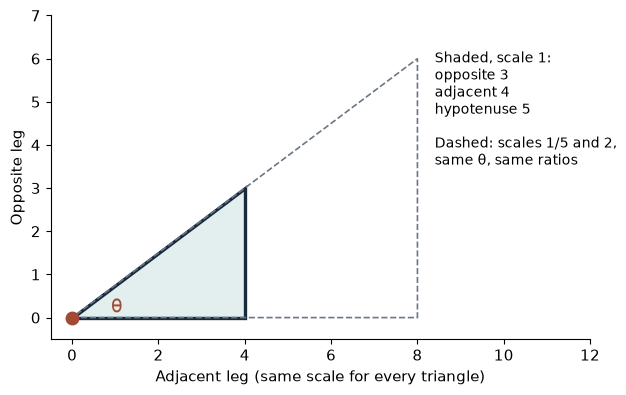

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for k, style, lw in [(Fraction(1, 5), "dashed", 1.2), (1, "solid", 2.4), (2, "dashed", 1.2)]:
    k = float(k)
    ax.add_patch(Polygon([(0, 0), (4 * k, 0), (4 * k, 3 * k)], closed=True,
                         facecolor="#e3efee" if k == 1 else "none", edgecolor=INK if k == 1 else GREY,
                         linewidth=lw, linestyle=style))
ax.plot(0, 0, "o", color=TERRA, markersize=9)
ax.text(0.9, 0.12, "\u03b8", fontsize=14, color=TERRA)
ax.text(8.4, 6.2, "Shaded, scale 1:\nopposite 3\nadjacent 4\nhypotenuse 5\n\nDashed: scales 1/5 and 2,\nsame \u03b8, same ratios", va="top", fontsize=10)
ax.set_xlim(-0.5, 12); ax.set_ylim(-0.5, 7); ax.set_aspect("equal")
ax.set_xlabel("Adjacent leg (same scale for every triangle)"); ax.set_ylabel("Opposite leg")
plt.tight_layout(); plt.show()

**What this shows:** scaling multiplies every side by the same number, so each ratio's top and bottom change together and the ratio stays put. The hypotenuse of the one-fifth triangle is 1, and its sine is still 3/5. Choosing the other acute angle swaps which leg is opposite, so sine and cosine trade places and tangent flips to 4/3.

**Where it stops working:** you need a right triangle, an acute angle chosen, and all sides in the same unit so the units cancel. Without a right angle, these three ratios do not apply.

## 2. Where the turning point lands

**Question:** at each quarter turn, what are the point's two coordinates, and what happens to tangent?

**The equations from the chapter:**

$$(\cos\theta, \sin\theta) \qquad\qquad \tan\theta=\frac{\sin\theta}{\cos\theta}$$

**What the symbols mean:** the unit circle has radius 1 and center $(0, 0)$. The angle $\theta$ starts on the positive horizontal axis and turns counterclockwise, measured in radians. Cosine is the across coordinate of the point, and sine is the up coordinate.

**Predict first:** turn to $\pi$. Which coordinate becomes negative, and is tangent defined there?

In [5]:
COS = {0: 1, 1: 0, 2: -1, 3: 0}
SIN = {0: 0, 1: 1, 2: 0, 3: -1}
NAMES = {0: "0", 1: "\u03c0/2", 2: "\u03c0", 3: "3\u03c0/2"}
def at_quarter(q):
    c, s = COS[q], SIN[q]
    say("Angle (radians)", NAMES[q])
    say("Point", f"({c}, {s})")
    say("Cosine", c)
    say("Sine", s)
    if c == 0:
        say("Tangent", "undefined (cosine is 0, so sin/cos would divide by zero)")
    else:
        say("Tangent", f"{s}/{c if c > 0 else f'({c})'} = {s // c}")
    say("Radius check", f"({c})^2 + ({s})^2 = {c*c + s*s}")

at_quarter(1)
print()
print("Other menu values:")
for q in [0, 2, 3]:
    at_quarter(q)
    print()

Angle (radians): π/2
Point: (0, 1)
Cosine: 0
Sine: 1
Tangent: undefined (cosine is 0, so sin/cos would divide by zero)
Radius check: (0)^2 + (1)^2 = 1

Other menu values:
Angle (radians): 0
Point: (1, 0)
Cosine: 1
Sine: 0
Tangent: 0/1 = 0
Radius check: (1)^2 + (0)^2 = 1

Angle (radians): π
Point: (-1, 0)
Cosine: -1
Sine: 0
Tangent: 0/(-1) = 0
Radius check: (-1)^2 + (0)^2 = 1

Angle (radians): 3π/2
Point: (0, -1)
Cosine: 0
Sine: -1
Tangent: undefined (cosine is 0, so sin/cos would divide by zero)
Radius check: (0)^2 + (-1)^2 = 1



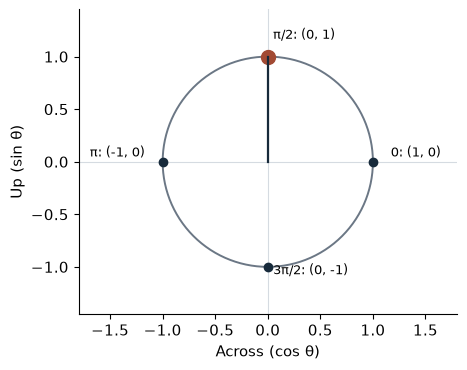

In [6]:
t = np.linspace(0, 2 * np.pi, 241)
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot(np.cos(t), np.sin(t), color=GREY, linewidth=1.4)
ax.axhline(0, color=LIGHT, linewidth=0.8); ax.axvline(0, color=LIGHT, linewidth=0.8)
for q in range(4):
    c, s = COS[q], SIN[q]
    ax.plot(c, s, "o", color=TERRA if q == 1 else INK, markersize=10 if q == 1 else 6)
    ax.text(c * 1.12 + (0.05 if c >= 0 else -0.05), s * 1.12 + 0.05, f"{NAMES[q]}: ({c}, {s})",
            ha="left" if c >= 0 else "right", fontsize=9)
ax.plot([0, 0], [0, 1], color=INK, linewidth=1.6)
ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.45, 1.45); ax.set_aspect("equal")
ax.set_xlabel("Across (cos \u03b8)"); ax.set_ylabel("Up (sin \u03b8)")
plt.tight_layout(); plt.show()

**What this shows:** the radius carries the point around. Its across position is cosine, its up position is sine, and the side of the circle decides each sign: left is negative across, below is negative up. At $\pi/2$ the point is $(0, 1)$, so $\cos = 0$ and $\sin = 1$, and tangent would need $1/0$, which is undefined.

**Where it stops working:** angles must start on the positive horizontal axis and turn counterclockwise. Change that convention and every label changes with it. And tangent is undefined wherever cosine is 0.

## 3. Unroll one coordinate into a wave

**Question:** if you record only one coordinate as the point turns, what shape does the record make?

**The equations from the chapter:**

$$(\pi/2,\, 1) \qquad\qquad 1,\ 0,\ -1,\ 0,\ 1$$

The first is the sine graph's high point. The second is the list of cosine values at the five quarter turns.

**What the symbols mean:** across the graph is the angle $\theta$ in radians (not a position on the circle). Up the graph is the recorded coordinate: sine records the height, cosine records the across position.

**Predict first:** stop at a half turn. Is the sine trace back at 0? Is the cosine trace?

In [7]:
SIN5 = {0: 0, 1: 1, 2: 0, 3: -1, 4: 0}
COS5 = {0: 1, 1: 0, 2: -1, 3: 0, 4: 1}
N5 = {0: "0", 1: "\u03c0/2", 2: "\u03c0", 3: "3\u03c0/2", 4: "2\u03c0"}
def unroll(name, upto):
    vals = SIN5 if name == "vertical (sine)" else COS5
    listed = ", ".join(str(vals[q]) for q in range(upto + 1))
    say("Recorded coordinate", name)
    say("Turned so far", f"{upto}/4 of a turn = {N5[upto]}")
    say("Values at each quarter turn", listed)
    say("Starting value", vals[0])
    print(f"The turn so far is {upto}/4 x 2\u03c0 = {N5[upto]}. The last marked point on the circle is ({COS5[upto]}, {SIN5[upto]}): ({COS5[upto]}) x ({COS5[upto]}) + ({SIN5[upto]}) x ({SIN5[upto]}) = {COS5[upto]**2 + SIN5[upto]**2}, still one unit from the center.")

unroll("vertical (sine)", 4)
print()
print("Same turn, recording the horizontal coordinate (cosine):")
unroll("horizontal (cosine)", 4)
print()
print("Stopping at a half turn:")
print("  sine: 0, 1, 0   (back at 0)")
print("  cosine: 1, 0, -1   (at -1, not back where it began)")

Recorded coordinate: vertical (sine)
Turned so far: 4/4 of a turn = 2π
Values at each quarter turn: 0, 1, 0, -1, 0
Starting value: 0
The turn so far is 4/4 x 2π = 2π. The last marked point on the circle is (1, 0): (1) x (1) + (0) x (0) = 1, still one unit from the center.

Same turn, recording the horizontal coordinate (cosine):
Recorded coordinate: horizontal (cosine)
Turned so far: 4/4 of a turn = 2π
Values at each quarter turn: 1, 0, -1, 0, 1
Starting value: 1
The turn so far is 4/4 x 2π = 2π. The last marked point on the circle is (1, 0): (1) x (1) + (0) x (0) = 1, still one unit from the center.

Stopping at a half turn:
  sine: 0, 1, 0   (back at 0)
  cosine: 1, 0, -1   (at -1, not back where it began)


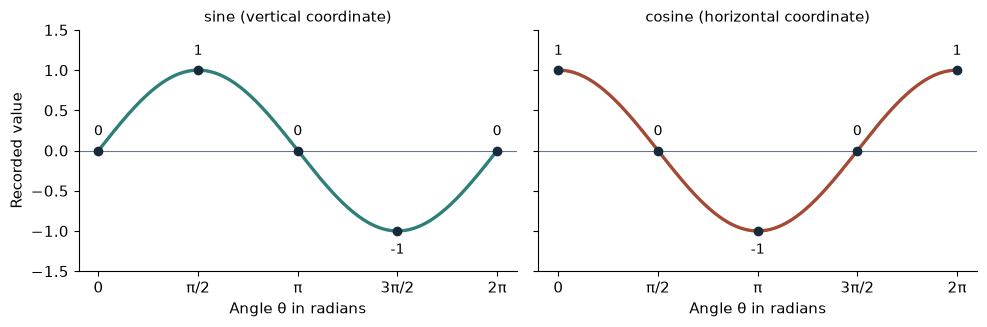

In [8]:
th = np.linspace(0, 2 * np.pi, 241)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (nm, f, vals, col) in zip(axes, [("sine (vertical coordinate)", np.sin, SIN5, TEAL),
                                          ("cosine (horizontal coordinate)", np.cos, COS5, TERRA)]):
    ax.plot(th, f(th), color=col, linewidth=2.4)
    ax.axhline(0, color=GREY, linewidth=0.8)
    for q in range(5):
        ax.plot(q * np.pi / 2, vals[q], "o", color=INK)
        ax.text(q * np.pi / 2, vals[q] + (0.15 if vals[q] >= 0 else -0.15), str(vals[q]),
                ha="center", va="bottom" if vals[q] >= 0 else "top", fontsize=10)
    ax.set_xticks([q * np.pi / 2 for q in range(5)])
    ax.set_xticklabels(["0", "\u03c0/2", "\u03c0", "3\u03c0/2", "2\u03c0"])
    ax.set_xlabel("Angle \u03b8 in radians"); ax.set_title(nm, fontsize=11); ax.set_ylim(-1.5, 1.5)
axes[0].set_ylabel("Recorded value")
plt.tight_layout(); plt.show()

**What this shows:** each quarter turn adds one marked value. Sine starts at 0 (mid height) and gives $0, 1, 0, -1, 0$; cosine starts at 1 (the right edge) and gives $1, 0, -1, 0, 1$. After one full turn, $2\pi$, the value is back where it began, and the pattern repeats. That repeating shape is the wave.

**Where it stops working:** the input is an angle in radians on a circle of radius 1. Equal values at 0 and $\pi$ (sine is 0 at both) do not make $\pi$ a period: the full cycle needs $2\pi$.

## 4. Midline first, then amplitude

**Question:** in the height model, how high and how low can the modeled height go?

**The equations from the chapter:**

$$h(\theta) = 2\ \text{m} + (1.5\ \text{m}) \sin\theta \qquad\qquad 2\ \text{m} - 1.5\ \text{m} = 0.5\ \text{m}$$

**What the symbols mean:** $h$ is the modeled height in meters and $\theta$ is the angle in radians. The 2 m is the midline. The 1.5 m is the amplitude: the distance from the midline up to the top, or down to the bottom.

**Predict first:** raise the midline to 3 m and keep the amplitude at 1.5 m. What are the new top and bottom?

In [9]:
def height_model(amp, mid):
    heights = [mid + amp * SIN5[q] for q in range(5)]
    g = lambda x: f"{x:g}"
    say("Midline", f"h = {g(mid)} m")
    say("Amplitude", f"{g(amp)} m")
    say("Maximum", f"{g(mid)} + {g(amp)} = {g(mid + amp)} m")
    say("Minimum", f"{g(mid)} - {g(amp)} = {g(mid - amp)} m")
    say("Heights at 0, \u03c0/2, \u03c0, 3\u03c0/2, 2\u03c0", ", ".join(g(h) for h in heights) + " m")
    print("Substituting at each quarter turn:")
    for q in range(5):
        print(f"  \u03b8 = {N5[q]}: h = {g(mid)} + {g(amp)} x ({SIN5[q]}) = {g(mid + amp * SIN5[q])} m")

height_model(1.5, 2)
print()
print("Other menu values (amplitude, midline): (1.5, 3), (0.5, 2), (0.5, 3), (2, 2), (2, 3), (0, 2), (0, 3)")
for amp, mid in [(1.5, 3), (0.5, 2), (2, 3), (0, 2)]:
    print(f"  amplitude {amp:g}, midline {mid:g}: top {mid:g} + {amp:g} = {mid+amp:g} m, bottom {mid:g} - {amp:g} = {mid-amp:g} m")

Midline: h = 2 m
Amplitude: 1.5 m
Maximum: 2 + 1.5 = 3.5 m
Minimum: 2 - 1.5 = 0.5 m
Heights at 0, π/2, π, 3π/2, 2π: 2, 3.5, 2, 0.5, 2 m
Substituting at each quarter turn:
  θ = 0: h = 2 + 1.5 x (0) = 2 m
  θ = π/2: h = 2 + 1.5 x (1) = 3.5 m
  θ = π: h = 2 + 1.5 x (0) = 2 m
  θ = 3π/2: h = 2 + 1.5 x (-1) = 0.5 m
  θ = 2π: h = 2 + 1.5 x (0) = 2 m

Other menu values (amplitude, midline): (1.5, 3), (0.5, 2), (0.5, 3), (2, 2), (2, 3), (0, 2), (0, 3)
  amplitude 1.5, midline 3: top 3 + 1.5 = 4.5 m, bottom 3 - 1.5 = 1.5 m
  amplitude 0.5, midline 2: top 2 + 0.5 = 2.5 m, bottom 2 - 0.5 = 1.5 m
  amplitude 2, midline 3: top 3 + 2 = 5 m, bottom 3 - 2 = 1 m
  amplitude 0, midline 2: top 2 + 0 = 2 m, bottom 2 - 0 = 2 m


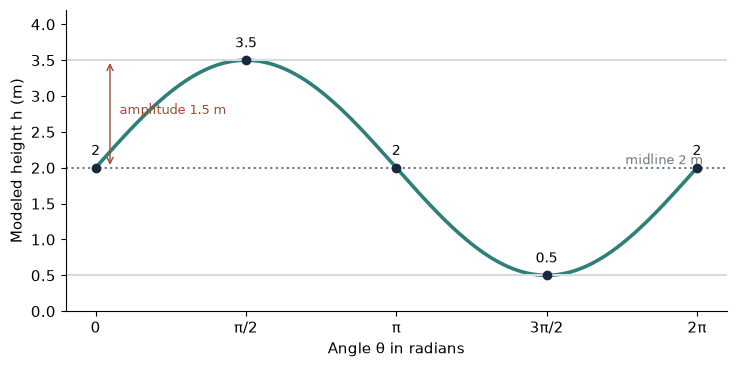

In [10]:
th = np.linspace(0, 2 * np.pi, 241)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(th, 2 + 1.5 * np.sin(th), color=TEAL, linewidth=2.6)
ax.axhline(2, color=GREY, linestyle="dotted"); ax.text(6.35, 2.05, "midline 2 m", color=GREY, ha="right", fontsize=9)
ax.axhline(3.5, color=LIGHT); ax.axhline(0.5, color=LIGHT)
for q in range(5):
    hq = 2 + 1.5 * SIN5[q]
    ax.plot(q * np.pi / 2, hq, "o", color=INK)
    ax.text(q * np.pi / 2, hq + 0.18, f"{hq:g}", ha="center", fontsize=10)
ax.annotate("", xy=(0.15, 3.5), xytext=(0.15, 2), arrowprops=dict(arrowstyle="<->", color=TERRA))
ax.text(0.25, 2.75, "amplitude 1.5 m", color=TERRA, fontsize=9)
ax.set_xticks([q * np.pi / 2 for q in range(5)]); ax.set_xticklabels(["0", "\u03c0/2", "\u03c0", "3\u03c0/2", "2\u03c0"])
ax.set_ylim(0, 4.2); ax.set_xlabel("Angle \u03b8 in radians"); ax.set_ylabel("Modeled height h (m)")
plt.tight_layout(); plt.show()

**What this shows:** sine runs from -1 to 1. Multiplying by the amplitude stretches that range, and adding the midline lifts it. So the top is midline plus amplitude (3.5 m) and the bottom is midline minus amplitude (0.5 m). After substituting into a sine model, check your answer against those two bounds: a height above 3.5 m or below 0.5 m does not belong to this model.

**Where it stops working:** this is a constructed model with the angle in radians. No time, speed or physical motion is supplied. With amplitude 0 the model is a flat line at the midline, with no least positive period.

## Practice

**1.** In a triangle with legs 6 and 8 and hypotenuse 10, what is the sine of the angle opposite the 6?

<details><summary>Show answer</summary>

Check the triangle: $6^2 + 8^2 = 36 + 64 = 100 = 10^2$.
Sine is opposite over hypotenuse: $6/10 = 3/5$. It is the same as in the 3-4-5 triangle, because every side doubled.

</details>

**2.** At $2\pi$, what are the cosine and sine, and why do they match the values at 0?

<details><summary>Show answer</summary>

Turning $2\pi$ is one full turn, and $0 + 2\pi$ reaches the same point $(1, 0)$.
So $\cos = 1$ and $\sin = 0$. Radius check: $1 \times 1 + 0 \times 0 = 1$.

</details>

**3.** What is the sine value at $5\pi/2$? And for $h = 2\ \text{m} + (1.5\ \text{m}) \sin\theta$, what is the height at $3\pi/2$?

<details><summary>Show answer</summary>

$5\pi/2 = \pi/2 + 2\pi$, one full turn past $\pi/2$, so it reaches the top of the circle again: $\sin = 1$.

At $3\pi/2$, $\sin = -1$, so $h = 2 + 1.5 \times (-1) = 2 - 1.5 = 0.5\ \text{m}$, the bottom of the model.

</details>